# Practical No. 06 — Retrieval-Augmented Generation (RAG) using a Pre-trained LLM

**Name:** Arjun Mankuskar


**PRN:** 202401110038

**Course practical:** Build a domain-specific question-answering application and compare answers from a pretrained language model with and without retrieval.

**Notebook outcome:** A complete, reproducible RAG pipeline with document ingestion, cleaning, chunking, sentence embeddings, a persistent Chroma vector database, similarity retrieval, pretrained LLM generation, source references, and a measurable comparison against an LLM-only baseline.

## Practical objectives

1. Load a collection of PDF, DOCX, TXT, Markdown, or CSV documents.
2. Extract and clean text, then split it into overlapping chunks.
3. Generate dense vector embeddings for each chunk.
4. Store and retrieve chunks using a vector database.
5. Generate grounded answers using a pretrained instruction-tuned LLM.
6. Compare RAG with the same LLM without retrieval and evaluate retrieval/answer quality.

## Workflow
Documents → Text Extraction → Text Cleaning → Chunking → Embeddings → Vector Database (ChromaDB)

User Question → Query Embedding → Similarity Search → Top-K Relevant Chunks → Pre-trained LLM + Context → RAG Answer

Same Question → Pre-trained LLM (Without Context) → LLM-only Answer

RAG Answer + LLM-only Answer → Performance Comparison → Final Evaluation

## 1. Install dependencies

Run this cell once in a fresh Colab/runtime. It installs the document readers, embedding model package, ChromaDB, and Hugging Face Transformers. PyTorch is normally preinstalled in Google Colab; the command below does not force-reinstall it.

In [2]:
%pip install -q sentence-transformers chromadb transformers accelerate pypdf python-docx matplotlib

## 2. Import libraries and configure the notebook

The embedding model converts text into vectors. ChromaDB stores those vectors and metadata. `google/flan-t5-base` is the pretrained instruction-tuned generator used for **both** experiments, ensuring the comparison changes retrieval rather than changing the LLM.

In [3]:
import os
import re
import json
import time
import hashlib
import unicodedata
import warnings
from pathlib import Path
from typing import List, Dict, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import chromadb
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from pypdf import PdfReader
from docx import Document as DocxDocument
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 30)

SEED = 42
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Runtime device: {DEVICE}")
if DEVICE == "cpu":
    print("Tip: select a GPU runtime in Colab for faster generation.")

# Change these settings when experimenting.
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
LLM_MODEL_NAME = "google/flan-t5-base"
CHUNK_SIZE_WORDS = 180
CHUNK_OVERLAP_WORDS = 35
TOP_K = 4
MAX_CONTEXT_CHARS = 4200

# Working directories. In Colab, files remain available for this runtime session.
try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
    WORK_DIR = Path("/content")
except ImportError:
    IN_COLAB = False
    WORK_DIR = Path.cwd()

DOCUMENTS_DIR = WORK_DIR / "rag_documents"
VECTOR_DB_DIR = WORK_DIR / "chroma_rag_db"
OUTPUT_DIR = WORK_DIR / "rag_outputs"
DOCUMENTS_DIR.mkdir(parents=True, exist_ok=True)
VECTOR_DB_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COLLECTION_NAME = "practical_06_rag_documents"
print("Documents folder:", DOCUMENTS_DIR.resolve())
print("Vector database folder:", VECTOR_DB_DIR.resolve())

Runtime device: cuda
Documents folder: /content/rag_documents
Vector database folder: /content/chroma_rag_db


## 3. Add your domain-specific documents

**Google Colab:** run the next cell and select multiple files. Supported formats are PDF, DOCX, TXT, MD, and CSV.

**Local Jupyter:** place your files in the `rag_documents` folder shown above, then run the cell. If no supported file is found, the notebook uses a clearly labelled AI/ML sample corpus so that the rest of the practical can still be demonstrated.

For scanned/image-only PDFs, text extraction may return little or no text. Use searchable PDFs or OCR the documents before uploading.

In [4]:
SUPPORTED_EXTENSIONS = {".pdf", ".docx", ".txt", ".md", ".csv"}

if IN_COLAB:
    from google.colab import files as colab_files
    print("Select your domain documents (you may select more than one file).")
    uploaded_files = colab_files.upload()
    for filename, file_bytes in uploaded_files.items():
        destination = DOCUMENTS_DIR / Path(filename).name
        destination.write_bytes(file_bytes)
        print(f"Saved: {destination.name}")
else:
    print(f"Place your documents in: {DOCUMENTS_DIR.resolve()}")

available_files = sorted(
    p for p in DOCUMENTS_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
)
print(f"Supported document files found: {len(available_files)}")
for p in available_files:
    print(" •", p.name)

Select your domain documents (you may select more than one file).


Saving RAG_Test.pdf to RAG_Test.pdf
Saved: RAG_Test.pdf
Supported document files found: 1
 • RAG_Test.pdf


## 4. Document extraction and text cleaning

The loader handles PDF page-by-page (preserving page numbers), DOCX paragraphs and tables, and text/Markdown/CSV files. Text is normalised and excessive whitespace/control characters are removed. Every extracted record retains its source filename so retrieved answers can cite the origin.

In [5]:
def clean_text(text: str) -> str:
    """Normalise extracted text while retaining useful punctuation and line breaks."""
    text = unicodedata.normalize("NFKC", str(text))
    text = text.replace("\x00", " ")
    text = re.sub(r"[\t\r ]+", " ", text)
    text = re.sub(r"\n\s*\n+", "\n", text)
    return text.strip()


def extract_file(path: Path) -> List[Dict[str, Any]]:
    """Extract text records from one supported file."""
    suffix = path.suffix.lower()
    records = []

    if suffix == ".pdf":
        reader = PdfReader(str(path))
        for page_number, page in enumerate(reader.pages, start=1):
            text = page.extract_text() or ""
            text = clean_text(text)
            if text:
                records.append({
                    "text": text,
                    "metadata": {"source": path.name, "page": page_number}
                })

    elif suffix == ".docx":
        doc = DocxDocument(str(path))
        parts = [p.text for p in doc.paragraphs if p.text.strip()]
        for table in doc.tables:
            for row in table.rows:
                parts.append(" | ".join(cell.text.strip() for cell in row.cells))
        text = clean_text("\n".join(parts))
        if text:
            records.append({"text": text, "metadata": {"source": path.name, "page": 1}})

    elif suffix in {".txt", ".md"}:
        text = path.read_text(encoding="utf-8", errors="replace")
        text = clean_text(text)
        if text:
            records.append({"text": text, "metadata": {"source": path.name, "page": 1}})

    elif suffix == ".csv":
        # Preserve column names and row structure as readable text.
        try:
            frame = pd.read_csv(path, encoding="utf-8", on_bad_lines="skip")
        except UnicodeDecodeError:
            frame = pd.read_csv(path, encoding="latin-1", on_bad_lines="skip")
        text = clean_text(frame.to_string(index=False))
        if text:
            records.append({"text": text, "metadata": {"source": path.name, "page": 1}})

    return records


raw_documents = []
extraction_errors = []
for file_path in available_files:
    try:
        extracted = extract_file(file_path)
        raw_documents.extend(extracted)
        if not extracted:
            extraction_errors.append(f"{file_path.name}: no extractable text found")
    except Exception as exc:
        extraction_errors.append(f"{file_path.name}: {type(exc).__name__}: {exc}")

print(f"Extracted text records: {len(raw_documents)}")
if extraction_errors:
    print("Extraction warnings:")
    for message in extraction_errors:
        print(" -", message)

Extracted text records: 7


## 5. Fallback sample corpus (used only when no uploaded text was extracted)

This compact sample collection is about **AI and machine learning fundamentals**. It is intentionally included so the notebook remains executable without external files. When your own documents were extracted successfully, this section does not replace them.

In [6]:
DEMO_CORPUS = {
    "01_machine_learning_fundamentals.txt": """
Machine learning fundamentals

Machine learning is a field of artificial intelligence in which a model learns patterns from data to make predictions or decisions. A typical machine-learning workflow includes defining the problem, collecting data, cleaning data, preparing features, splitting the data, training a model, validating and tuning it, testing it, and monitoring its performance.

Supervised learning uses labelled examples. Classification predicts a category such as spam or not spam, while regression predicts a numeric value such as a house price. Unsupervised learning works with data that has no target labels. Clustering groups similar observations, and dimensionality reduction represents data using fewer features.

A dataset is commonly separated into training, validation, and test sets. The training set fits model parameters, the validation set supports model selection and hyperparameter tuning, and the test set estimates performance on unseen data. The test set should not be repeatedly used during tuning.

Overfitting occurs when a model learns noise or details specific to the training examples and performs poorly on unseen data. Regularisation, simpler models, more representative data, and cross-validation can help reduce overfitting. Underfitting occurs when a model is too simple to capture important patterns.
""",
    "02_embeddings_and_vector_search.txt": """
Text embeddings and vector search

A text embedding model maps a text passage into a dense numeric vector. Passages with related meanings are expected to have nearby vectors in the embedding space. Embeddings enable semantic retrieval, where a search can find conceptually related passages even when the wording is not identical.

Chunking divides long documents into smaller passages before embedding. Chunk size controls the amount of text in each passage. Very small chunks may lose context; very large chunks may contain unrelated information and make retrieval less precise. Chunk overlap repeats a small part of adjacent chunks so that information near a boundary is less likely to be lost. The chunk size and overlap should be selected based on document structure and tested empirically.

Cosine similarity measures the angle-based similarity between two vectors. A larger cosine similarity generally indicates that two embeddings point in a more similar direction. A vector database stores embeddings together with their text and metadata, and performs nearest-neighbour search to return relevant passages for a query.

Metadata such as source filename, page number, and chunk index makes retrieval results traceable. Metadata should be retained with every chunk so that the system can display the source of an answer.
""",
    "03_rag_pipeline_and_evaluation.txt": """
Retrieval-Augmented Generation architecture

Retrieval-Augmented Generation (RAG) combines information retrieval with text generation. During the indexing stage, documents are loaded, cleaned, split into chunks, converted into embeddings, and stored in a vector database. During a query, the question is embedded, the vector database retrieves the top-k most similar chunks, and the retrieved text is inserted into a prompt for a language model.

The main RAG stages are document ingestion, text preprocessing, chunking, embedding generation, vector indexing, query embedding, similarity-based retrieval, context construction, and answer generation. A useful RAG answer should be relevant to the question and supported by the retrieved context. Source labels can be included in the context so the model can cite supporting documents.

An LLM-only baseline receives the question but no retrieved domain documents. Comparing it with RAG helps show whether retrieval improves access to domain-specific facts. Both approaches should use the same language model and comparable generation settings for a fair experiment.

RAG does not guarantee factual correctness. Retrieval may return irrelevant or incomplete passages, the model may misinterpret context, and a prompt may exceed the model's input limit. Evaluation should examine retrieval relevance, answer relevance, factual support, completeness, latency, and hallucinations. A system should state that the supplied documents do not contain an answer when the retrieved evidence is insufficient instead of inventing a fact.
""",
    "04_prompt_design_and_limitations.txt": """
Prompt design and responsible limitations

A grounded RAG prompt tells the language model to answer using only the supplied context, distinguish evidence from assumptions, and say when the context does not contain the answer. Retrieved passages should be labelled with source identifiers such as [S1] and [S2]. The model should not create a source citation that was not supplied to it.

Top-k is the number of passages returned by vector search. A small top-k may omit relevant evidence, while a large top-k can introduce noise and consume the language model's context window. Retrieval settings should be evaluated on representative questions rather than selected from one example.

A practical evaluation set should contain questions with known supporting documents and reference answers. Precision at k measures the fraction of retrieved passages that are relevant. Recall at k measures how many known relevant documents were retrieved. Mean reciprocal rank (MRR) gives more credit when the first relevant result appears near the top. These retrieval metrics do not, by themselves, prove that a generated answer is correct; human review of grounding and completeness is also important.
"""
}

if not raw_documents:
    print("No usable uploaded text was found. Activating the built-in sample corpus.")
    raw_documents = [
        {"text": clean_text(text), "metadata": {"source": filename, "page": 1}}
        for filename, text in DEMO_CORPUS.items()
    ]
    USING_DEMO_CORPUS = True
else:
    USING_DEMO_CORPUS = False

print("Corpus mode:", "BUILT-IN DEMO" if USING_DEMO_CORPUS else "UPLOADED DOCUMENTS")
print("Text records:", len(raw_documents))
print("Source files:", sorted({r["metadata"]["source"] for r in raw_documents}))

Corpus mode: UPLOADED DOCUMENTS
Text records: 7
Source files: ['RAG_Test.pdf']


## 6. Chunk the documents

The baseline configuration uses **180 words per chunk** and **35 words of overlap**. Overlap helps preserve context across adjacent chunks. These are starting values, not universal optimums; the best settings depend on the documents and evaluation questions.

In [7]:
def split_into_chunks(text: str, chunk_size: int = CHUNK_SIZE_WORDS,
                      overlap: int = CHUNK_OVERLAP_WORDS) -> List[str]:
    words = clean_text(text).split()
    if not words:
        return []
    if chunk_size <= 0 or overlap < 0 or overlap >= chunk_size:
        raise ValueError("Require chunk_size > overlap >= 0.")

    chunks = []
    step = chunk_size - overlap
    for start in range(0, len(words), step):
        chunk_words = words[start:start + chunk_size]
        if not chunk_words:
            break
        chunks.append(" ".join(chunk_words))
        if start + chunk_size >= len(words):
            break
    return chunks


chunks = []
for record in raw_documents:
    source = record["metadata"]["source"]
    page = int(record["metadata"].get("page", 1))
    for chunk_index, chunk_text in enumerate(split_into_chunks(record["text"]), start=1):
        digest = hashlib.md5(
            f"{source}|{page}|{chunk_index}|{chunk_text}".encode("utf-8")
        ).hexdigest()[:10]
        chunks.append({
            "id": f"chunk_{digest}",
            "text": chunk_text,
            "metadata": {
                "source": source,
                "page": page,
                "chunk_index": chunk_index,
            }
        })

if not chunks:
    raise ValueError("No text chunks were created. Check your uploaded documents.")

chunk_table = pd.DataFrame([
    {
        "chunk_id": item["id"],
        "source": item["metadata"]["source"],
        "page": item["metadata"]["page"],
        "chunk_index": item["metadata"]["chunk_index"],
        "word_count": len(item["text"].split()),
        "preview": item["text"][:260] + ("…" if len(item["text"]) > 260 else "")
    }
    for item in chunks
])

print(f"Created {len(chunks)} chunks from {len(raw_documents)} extracted text records.")
print(f"Chunk configuration: {CHUNK_SIZE_WORDS} words; overlap: {CHUNK_OVERLAP_WORDS} words.")
display(chunk_table.head(10))

Created 20 chunks from 7 extracted text records.
Chunk configuration: 180 words; overlap: 35 words.


,chunk_id,source,page,chunk_index,word_count,preview
0,chunk_6ac75ae86e,RAG_Test.pdf,1,1,180,"Searchable PDF for document extraction, chunking, embeddings and retrieval Page 1 RAG Practical Test Document AI and Machine Learning Fundamentals | Designed for Practical No. ..."
1,chunk_dde35e0caa,RAG_Test.pdf,1,2,180,"of writing a separate rule for every possible situation, a developer supplies data and a learning procedure that estimates a model. A machine-learning model is the result of tr..."
2,chunk_86d6280020,RAG_Test.pdf,1,3,103," Reinforcement learning: an agent learns by interacting with an environment. It receives rewards or penalties and aims to learn actions that maximise cumulative reward. AI, ML..."
3,chunk_dbfae249bd,RAG_Test.pdf,2,1,180,"PRACTICAL NO. 06 | RAG TEST DOCUMENT Searchable PDF for document extraction, chunking, embeddings and retrieval Page 2 2. Machine Learning Workflow and Evaluation A reliable ma..."
4,chunk_3a62872629,RAG_Test.pdf,2,2,180,"optimistic. Preprocessing must be fitted carefully. For example, a scaler should be fitted on the training data and then applied to the validation and test data. The same rule ..."
5,chunk_3940f61528,RAG_Test.pdf,2,3,88,"predicted positives are truly positive, while recall measures how many actual positives are found. The F1-score is the harmonic mean of precision and recall. For regression, me..."
6,chunk_bb05035dd4,RAG_Test.pdf,3,1,180,"PRACTICAL NO. 06 | RAG TEST DOCUMENT Searchable PDF for document extraction, chunking, embeddings and retrieval Page 3 3. Text Embeddings and Semantic Search A text embedding i..."
7,chunk_47ee6c1ae1,RAG_Test.pdf,3,2,180,a user asks a question using different wording from the source document. Cosine similarity compares the direction of two vectors. A larger cosine similarity generally indicates...
8,chunk_12969904ee,RAG_Test.pdf,3,3,90,each input text. The same model must encode both document chunks and user questions so that their vectors belong to the same embedding space. Using unrelated embedding models f...
9,chunk_1d5bf7246c,RAG_Test.pdf,4,1,180,"PRACTICAL NO. 06 | RAG TEST DOCUMENT Searchable PDF for document extraction, chunking, embeddings and retrieval Page 4 4. Document Processing, Chunking, and Metadata A document..."


## 7. Generate embeddings

`all-MiniLM-L6-v2` is a compact sentence-transformer that produces a 384-dimensional dense vector. The same embedding model is used for document chunks and user questions so that both are represented in the same vector space.

In [8]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=DEVICE)
chunk_texts = [item["text"] for item in chunks]

chunk_embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

print("Embedding matrix shape:", chunk_embeddings.shape)
print("Embedding vector dimension:", chunk_embeddings.shape[1])
assert len(chunk_embeddings) == len(chunks)
assert np.isfinite(chunk_embeddings).all(), "Embeddings contain non-finite values."

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix shape: (20, 384)
Embedding vector dimension: 384


## 8. Create and populate the Chroma vector database

ChromaDB is used as the vector database. Each record stores the chunk text, embedding, and metadata (`source`, `page`, and `chunk_index`). The database is persisted in `chroma_rag_db` for this runtime. To keep reruns reproducible, this notebook recreates its named collection rather than appending duplicate records.

In [9]:
chroma_client = chromadb.PersistentClient(path=str(VECTOR_DB_DIR))

try:
    chroma_client.delete_collection(name=COLLECTION_NAME)
except Exception:
    pass

collection = chroma_client.create_collection(
    name=COLLECTION_NAME,
    metadata={"hnsw:space": "cosine"}
)

collection.add(
    ids=[item["id"] for item in chunks],
    documents=chunk_texts,
    metadatas=[item["metadata"] for item in chunks],
    embeddings=chunk_embeddings.astype(float).tolist(),
)

print("Vector database created successfully.")
print("Collection:", COLLECTION_NAME)
print("Indexed vectors:", collection.count())
assert collection.count() == len(chunks)

Vector database created successfully.
Collection: practical_06_rag_documents
Indexed vectors: 20


## 9. Implement semantic retrieval

The query is embedded with the same sentence-transformer. Chroma returns the top-k nearest chunks using cosine distance. The displayed similarity is calculated as `1 − cosine_distance`; it is a ranking signal, **not** a calibrated probability of correctness.

In [10]:
def retrieve(question: str, top_k: int = TOP_K) -> List[Dict[str, Any]]:
    question = clean_text(question)
    if not question:
        raise ValueError("Question cannot be empty.")
    n_results = min(max(1, int(top_k)), collection.count())
    query_vector = embedding_model.encode(
        [question], convert_to_numpy=True, normalize_embeddings=True
    )[0]
    result = collection.query(
        query_embeddings=[query_vector.astype(float).tolist()],
        n_results=n_results,
        include=["documents", "metadatas", "distances"]
    )

    retrieved = []
    for rank, (doc, metadata, distance) in enumerate(zip(
        result["documents"][0],
        result["metadatas"][0],
        result["distances"][0]
    ), start=1):
        retrieved.append({
            "rank": rank,
            "text": doc,
            "metadata": metadata,
            "cosine_distance": float(distance),
            "similarity": float(1.0 - distance),
        })
    return retrieved


def show_retrieved_chunks(question: str, top_k: int = TOP_K) -> pd.DataFrame:
    results = retrieve(question, top_k=top_k)
    table = pd.DataFrame([
        {
            "rank": r["rank"],
            "source": r["metadata"].get("source"),
            "page": r["metadata"].get("page"),
            "chunk": r["metadata"].get("chunk_index"),
            "cosine_similarity": round(r["similarity"], 4),
            "retrieved_text": r["text"][:450] + ("…" if len(r["text"]) > 450 else "")
        }
        for r in results
    ])
    display(table)
    return table

# Retrieval-only smoke test
retrieval_test_question = "What are the main stages of a retrieval-augmented generation system?"
retrieval_test_results = show_retrieved_chunks(retrieval_test_question, top_k=TOP_K)
assert len(retrieval_test_results) > 0, "Retrieval returned no results."

,rank,source,page,chunk,cosine_similarity,retrieved_text
0,1,RAG_Test.pdf,5,1,0.5169,"PRACTICAL NO. 06 | RAG TEST DOCUMENT Searchable PDF for document extraction, chunking, embeddings and retrieval Page 5 5. Retrieval-Augmented Generation (RAG) Pipeline Retrieva..."
1,2,RAG_Test.pdf,7,1,0.3861,"PRACTICAL NO. 06 | RAG TEST DOCUMENT Searchable PDF for document extraction, chunking, embeddings and retrieval Page 7 7. Questions for Testing the RAG Application Use these qu..."
2,3,RAG_Test.pdf,5,2,0.3835,returns the top-k most similar chunks. Top-k means the number of retrieved passages. The application combines these passages into a context and sends the context and question t...
3,4,RAG_Test.pdf,2,1,0.3723,"PRACTICAL NO. 06 | RAG TEST DOCUMENT Searchable PDF for document extraction, chunking, embeddings and retrieval Page 2 2. Machine Learning Workflow and Evaluation A reliable ma..."


## 10. Load the pretrained LLM

The notebook uses `google/flan-t5-base`, an instruction-tuned pretrained sequence-to-sequence model. It is downloaded from Hugging Face the first time the cell runs and cached for later runs. No API key is required. The same tokenizer, model, and generation settings are used for RAG and LLM-only answers.

In [11]:
print("Loading pretrained generator:", LLM_MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)
llm = AutoModelForSeq2SeqLM.from_pretrained(LLM_MODEL_NAME)
llm = llm.to(DEVICE)
llm.eval()
print("LLM loaded on:", DEVICE)

Loading pretrained generator: google/flan-t5-base


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

LLM loaded on: cuda


## 11. Build prompts and generate answers

The RAG prompt explicitly restricts the answer to retrieved evidence and requests citations such as `[S1]`. The LLM-only prompt receives no retrieved context. If the supplied context does not contain the answer, the RAG system is instructed to say so rather than inventing unsupported details.

In [12]:
def generate_from_prompt(prompt: str, max_new_tokens: int = 180) -> str:
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
    with torch.inference_mode():
        output_ids = llm.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            do_sample=False,
            no_repeat_ngram_size=3,
            repetition_penalty=1.08,
            early_stopping=True,
        )
    answer = tokenizer.decode(output_ids[0], skip_special_tokens=True).strip()
    return answer if answer else "The model did not generate an answer."


def build_rag_context(retrieved: List[Dict[str, Any]], max_chars: int = MAX_CONTEXT_CHARS) -> str:
    sections = []
    used_chars = 0
    for index, item in enumerate(retrieved, start=1):
        source = item["metadata"].get("source", "unknown source")
        page = item["metadata"].get("page", "?")
        section = f"[S{index}] Source: {source}, page: {page}\n{item['text']}"
        remaining = max_chars - used_chars
        if remaining <= 0:
            break
        if len(section) > remaining:
            section = section[:remaining]
        sections.append(section)
        used_chars += len(section)
    return "\n\n".join(sections)


def answer_with_rag(question: str, top_k: int = TOP_K) -> Dict[str, Any]:
    start = time.perf_counter()
    retrieved = retrieve(question, top_k=top_k)
    context = build_rag_context(retrieved)
    prompt = f"""You are a careful question-answering assistant.
Answer the QUESTION using only the RETRIEVED CONTEXT below.
Do not use outside knowledge. Do not invent names, numbers, facts, or citations.
Cite supporting passages with their exact labels, for example [S1] or [S2].
If the context does not contain enough evidence, respond: The provided documents do not contain enough information to answer this question.
Write a concise, direct answer.

RETRIEVED CONTEXT:
{context}

QUESTION: {question}
ANSWER:"""
    answer = generate_from_prompt(prompt)
    elapsed = time.perf_counter() - start
    return {
        "question": question,
        "answer": answer,
        "retrieved": retrieved,
        "context": context,
        "latency_seconds": elapsed,
    }


def answer_llm_only(question: str) -> Dict[str, Any]:
    start = time.perf_counter()
    prompt = f"""Answer the question using your pretrained knowledge.
No external documents or retrieved context are provided.
If you are unsure, state that you are unsure instead of inventing details.
Give a concise, direct answer.

QUESTION: {question}
ANSWER:"""
    answer = generate_from_prompt(prompt)
    elapsed = time.perf_counter() - start
    return {"question": question, "answer": answer, "latency_seconds": elapsed}


# First end-to-end test
sample_question = "What are the main stages of a RAG pipeline?"
llm_only_demo = answer_llm_only(sample_question)
rag_demo = answer_with_rag(sample_question)

display(Markdown("### LLM-only answer (no retrieved documents)"))
print(llm_only_demo["answer"])
display(Markdown("### RAG answer (with retrieved document context)"))
print(rag_demo["answer"])
print("\nRetrieved sources:")
for idx, item in enumerate(rag_demo["retrieved"], start=1):
    print(f"[S{idx}] {item['metadata'].get('source')} | page {item['metadata'].get('page')} | similarity {item['similarity']:.3f}")

### LLM-only answer (no retrieved documents)

RAG is a pipeline that connects a power station to a transmission line.


### RAG answer (with retrieved document context)

To fit model parameters. The validation set is used to compare models and tune hyperparameters.

Retrieved sources:
[S1] RAG_Test.pdf | page 2 | similarity 0.374
[S2] RAG_Test.pdf | page 7 | similarity 0.359
[S3] RAG_Test.pdf | page 5 | similarity 0.331
[S4] RAG_Test.pdf | page 4 | similarity 0.325


## 12. Prepare a small evaluation set

The sample questions below are aligned with the built-in demo corpus. **When you upload your own documents, edit these questions, expected source filenames, reference answers and keywords** so they describe facts actually present in your collection. An evaluation set should cover different parts of the domain, not repeat one question in different words.

In [13]:
EVALUATION_QUESTIONS = [
    {
        "question": "What are the main stages in a basic RAG pipeline?",
        "expected_sources": ["03_rag_pipeline_and_evaluation.txt"],
        "reference_answer": "Documents are ingested, cleaned and chunked; chunks are embedded and indexed; a question is embedded; relevant chunks are retrieved and supplied to the LLM for answer generation.",
        "keywords": ["ingestion", "chunk", "embedding", "retriev", "generation"],
    },
    {
        "question": "What is a text embedding and how is it used in semantic search?",
        "expected_sources": ["02_embeddings_and_vector_search.txt"],
        "reference_answer": "A text embedding maps a passage to a dense numeric vector. Semantic search compares the query vector with stored passage vectors to retrieve passages with related meanings.",
        "keywords": ["vector", "numeric", "semantic", "similar", "retriev"],
    },
    {
        "question": "Explain chunk size and chunk overlap. Why are both important?",
        "expected_sources": ["02_embeddings_and_vector_search.txt"],
        "reference_answer": "Chunk size controls the amount of text in each passage. Overlap repeats some text between adjacent chunks so context near chunk boundaries is less likely to be lost.",
        "keywords": ["chunk size", "overlap", "context", "boundary"],
    },
    {
        "question": "Why should a RAG system admit when the retrieved context is insufficient?",
        "expected_sources": ["03_rag_pipeline_and_evaluation.txt", "04_prompt_design_and_limitations.txt"],
        "reference_answer": "Retrieval can be incomplete or irrelevant. The system should not invent unsupported facts; it should clearly state that the documents do not contain enough evidence to answer.",
        "keywords": ["incomplete", "irrelevant", "invent", "unsupported", "evidence"],
    },
]

if not USING_DEMO_CORPUS:
    print("IMPORTANT: The evaluation set is still based on the built-in AI/ML demo corpus.")
    print("Edit EVALUATION_QUESTIONS so expected_sources and reference answers match your uploaded documents before interpreting the scores.")

display(pd.DataFrame(EVALUATION_QUESTIONS)[["question", "expected_sources", "reference_answer"]])

IMPORTANT: The evaluation set is still based on the built-in AI/ML demo corpus.
Edit EVALUATION_QUESTIONS so expected_sources and reference answers match your uploaded documents before interpreting the scores.


,question,expected_sources,reference_answer
0,What are the main stages in a basic RAG pipeline?,[03_rag_pipeline_and_evaluation.txt],"Documents are ingested, cleaned and chunked; chunks are embedded and indexed; a question is embedded; relevant chunks are retrieved and supplied to the LLM for answer generation."
1,What is a text embedding and how is it used in semantic search?,[02_embeddings_and_vector_search.txt],A text embedding maps a passage to a dense numeric vector. Semantic search compares the query vector with stored passage vectors to retrieve passages with related meanings.
2,Explain chunk size and chunk overlap. Why are both important?,[02_embeddings_and_vector_search.txt],Chunk size controls the amount of text in each passage. Overlap repeats some text between adjacent chunks so context near chunk boundaries is less likely to be lost.
3,Why should a RAG system admit when the retrieved context is insufficient?,"[03_rag_pipeline_and_evaluation.txt, 04_prompt_design_and_limitations.txt]",Retrieval can be incomplete or irrelevant. The system should not invent unsupported facts; it should clearly state that the documents do not contain enough evidence to answer.


## 13. Compare RAG with the LLM-only baseline

The experiment uses the **same pretrained LLM** for both conditions:

- **LLM-only:** question → pretrained LLM.
- **RAG:** question → embedding → top-k retrieval → context + question → the same pretrained LLM.

Retrieval metrics are calculated from the expected source filenames you specify in the evaluation set. Keyword coverage is a simple diagnostic proxy based on the reference answer; it is not a complete or definitive measure of factual correctness. Review the actual answers and sources as well.

In [14]:
def keyword_coverage(answer: str, keywords: List[str]) -> float:
    if not keywords:
        return float("nan")
    answer_lower = answer.lower()
    matched = sum(1 for keyword in keywords if keyword.lower() in answer_lower)
    return matched / len(keywords)


def retrieval_metrics(retrieved: List[Dict[str, Any]], expected_sources: List[str], k: int) -> Dict[str, float]:
    expected = set(expected_sources)
    top_results = retrieved[:k]
    if not expected or not top_results:
        return {f"Precision@{k}": 0.0, f"Recall@{k}": 0.0, "MRR": 0.0}

    relevant_flags = [r["metadata"].get("source") in expected for r in top_results]
    precision = sum(relevant_flags) / k
    found_sources = {r["metadata"].get("source") for r, relevant in zip(top_results, relevant_flags) if relevant}
    recall = len(found_sources) / len(expected)
    reciprocal_rank = 0.0
    for rank, relevant in enumerate(relevant_flags, start=1):
        if relevant:
            reciprocal_rank = 1.0 / rank
            break
    return {f"Precision@{k}": precision, f"Recall@{k}": min(1.0, recall), "MRR": reciprocal_rank}


evaluation_rows = []
for item in EVALUATION_QUESTIONS:
    question = item["question"]
    print("Evaluating:", question)

    baseline = answer_llm_only(question)
    rag_result = answer_with_rag(question, top_k=TOP_K)
    metrics = retrieval_metrics(rag_result["retrieved"], item["expected_sources"], TOP_K)

    retrieved_sources = [r["metadata"].get("source", "unknown") for r in rag_result["retrieved"]]
    unique_sources = list(dict.fromkeys(retrieved_sources))

    evaluation_rows.append({
        "question": question,
        "llm_only_answer": baseline["answer"],
        "rag_answer": rag_result["answer"],
        "expected_sources": ", ".join(item["expected_sources"]),
        "retrieved_sources": ", ".join(unique_sources),
        f"Precision@{TOP_K}": metrics[f"Precision@{TOP_K}"],
        f"Recall@{TOP_K}": metrics[f"Recall@{TOP_K}"],
        "MRR": metrics["MRR"],
        "LLM-only keyword coverage": keyword_coverage(baseline["answer"], item["keywords"]),
        "RAG keyword coverage": keyword_coverage(rag_result["answer"], item["keywords"]),
        "LLM-only latency (s)": baseline["latency_seconds"],
        "RAG latency (s)": rag_result["latency_seconds"],
    })

evaluation_results = pd.DataFrame(evaluation_rows)
display(evaluation_results.round(3))

Evaluating: What are the main stages in a basic RAG pipeline?
Evaluating: What is a text embedding and how is it used in semantic search?
Evaluating: Explain chunk size and chunk overlap. Why are both important?
Evaluating: Why should a RAG system admit when the retrieved context is insufficient?


,question,llm_only_answer,rag_answer,expected_sources,retrieved_sources,Precision@4,Recall@4,MRR,LLM-only keyword coverage,RAG keyword coverage,LLM-only latency (s),RAG latency (s)
0,What are the main stages in a basic RAG pipeline?,RAG pipelines are a series of pipelines that are connected to each other by a conductor. The conductor is connected to the conductor through a sleeve.,[S1] or [S2],03_rag_pipeline_and_evaluation.txt,RAG_Test.pdf,0.0,0.0,0.0,0.0,0.0,1.075,0.402
1,What is a text embedding and how is it used in semantic search?,text embedding,A text embedding is a dense numeric representation of a piece of text.,02_embeddings_and_vector_search.txt,RAG_Test.pdf,0.0,0.0,0.0,0.0,0.2,0.377,0.623
2,Explain chunk size and chunk overlap. Why are both important?,The size of a chunk depends on how large it is.,A PDF reader extracts text from searchable PDF pages. A CSV reader converts rows and columns names.,02_embeddings_and_vector_search.txt,RAG_Test.pdf,0.0,0.0,0.0,0.0,0.0,0.419,0.557
3,Why should a RAG system admit when the retrieved context is insufficient?,a RAG system should admit when the retrieved context is insufficient.,"RAG is most useful when the document collection is relevant, extraction is reliable, retrieval is appropriate, and the prompt encourages evidence-based answers.","03_rag_pipeline_and_evaluation.txt, 04_prompt_design_and_limitations.txt",RAG_Test.pdf,0.0,0.0,0.0,0.0,0.2,0.341,0.774


### 13.1 Aggregate scores and visual comparison

Interpret the metrics together. High retrieval scores indicate that expected source documents were found; they do **not** guarantee that the LLM used them correctly. Low latency may depend on hardware, caching, model loading and document size. Record the runtime environment when reporting results.

Mean evaluation metrics:


,Mean score
Precision@4,0.0
Recall@4,0.0
MRR,0.0
LLM-only keyword coverage,0.0
RAG keyword coverage,0.1


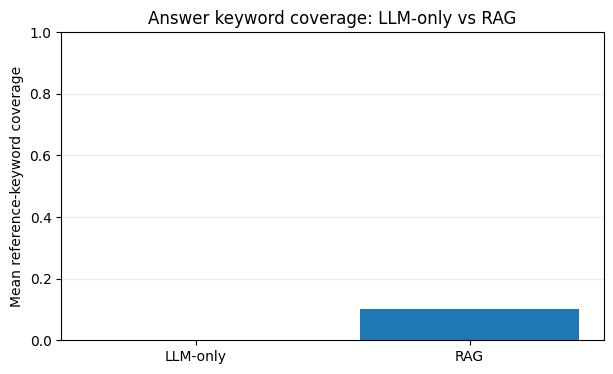

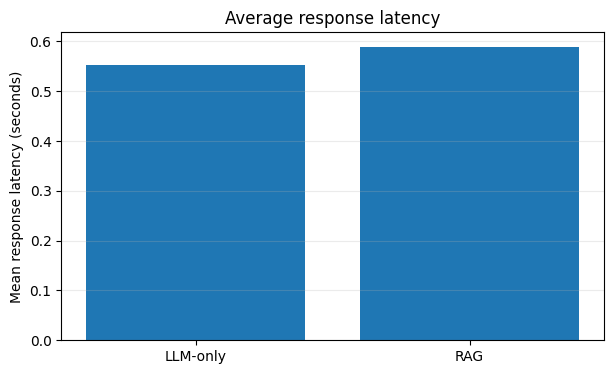

In [15]:
metric_columns = [f"Precision@{TOP_K}", f"Recall@{TOP_K}", "MRR",
                  "LLM-only keyword coverage", "RAG keyword coverage"]
summary_metrics = evaluation_results[metric_columns].mean(numeric_only=True).to_frame("Mean score")
print("Mean evaluation metrics:")
display(summary_metrics.round(3))

# Figure 1: keyword coverage comparison
coverage_means = [
    evaluation_results["LLM-only keyword coverage"].mean(),
    evaluation_results["RAG keyword coverage"].mean(),
]
plt.figure(figsize=(7, 4))
plt.bar(["LLM-only", "RAG"], coverage_means)
plt.ylim(0, 1)
plt.ylabel("Mean reference-keyword coverage")
plt.title("Answer keyword coverage: LLM-only vs RAG")
plt.grid(axis="y", alpha=0.25)
plt.show()

# Figure 2: average response latency
latency_means = [
    evaluation_results["LLM-only latency (s)"].mean(),
    evaluation_results["RAG latency (s)"].mean(),
]
plt.figure(figsize=(7, 4))
plt.bar(["LLM-only", "RAG"], latency_means)
plt.ylabel("Mean response latency (seconds)")
plt.title("Average response latency")
plt.grid(axis="y", alpha=0.25)
plt.show()

### 13.2 Human review of answer quality

Use the following table during testing or viva. Rate each answer from **1 (poor) to 5 (excellent)**. Groundedness means the answer is supported by the retrieved passages; completeness means it covers the important parts of the question. Mark hallucination risk as high when the answer states facts that are not supported by the documents.

In [16]:
human_review_template = evaluation_results[["question", "llm_only_answer", "rag_answer", "retrieved_sources"]].copy()
human_review_template["LLM-only relevance (1-5)"] = ""
human_review_template["RAG relevance (1-5)"] = ""
human_review_template["RAG groundedness (1-5)"] = ""
human_review_template["RAG completeness (1-5)"] = ""
human_review_template["RAG hallucination risk (Low/Medium/High)"] = ""
display(human_review_template)

,question,llm_only_answer,rag_answer,retrieved_sources,LLM-only relevance (1-5),RAG relevance (1-5),RAG groundedness (1-5),RAG completeness (1-5),RAG hallucination risk (Low/Medium/High)
0,What are the main stages in a basic RAG pipeline?,RAG pipelines are a series of pipelines that are connected to each other by a conductor. The conductor is connected to the conductor through a sleeve.,[S1] or [S2],RAG_Test.pdf,,,,,
1,What is a text embedding and how is it used in semantic search?,text embedding,A text embedding is a dense numeric representation of a piece of text.,RAG_Test.pdf,,,,,
2,Explain chunk size and chunk overlap. Why are both important?,The size of a chunk depends on how large it is.,A PDF reader extracts text from searchable PDF pages. A CSV reader converts rows and columns names.,RAG_Test.pdf,,,,,
3,Why should a RAG system admit when the retrieved context is insufficient?,a RAG system should admit when the retrieved context is insufficient.,"RAG is most useful when the document collection is relevant, extraction is reliable, retrieval is appropriate, and the prompt encourages evidence-based answers.",RAG_Test.pdf,,,,,


## 14. Interactive application demonstration

Run this cell and call `ask_rag("your question")` with questions about your uploaded document collection. The function prints the answer and the retrieved source passages. This is the core live demonstration for the practical.

In [17]:
def ask_rag(question: str, top_k: int = TOP_K, show_sources: bool = True) -> str:
    result = answer_with_rag(question, top_k=top_k)
    display(Markdown("### Question"))
    print(question)
    display(Markdown("### RAG answer"))
    print(result["answer"])

    if show_sources:
        display(Markdown("### Retrieved evidence"))
        for index, item in enumerate(result["retrieved"], start=1):
            source = item["metadata"].get("source", "unknown")
            page = item["metadata"].get("page", "?")
            print(f"[S{index}] {source} | page {page} | similarity={item['similarity']:.3f}")
            print(item["text"][:700] + ("…" if len(item["text"]) > 700 else ""))
            print("-" * 80)
    print(f"Total RAG latency: {result['latency_seconds']:.2f} seconds")
    return result["answer"]

# Change this to a question answered by your uploaded documents.
ask_rag("What is the role of chunk overlap in a RAG system?")

### Question

What is the role of chunk overlap in a RAG system?


### RAG answer

[S2]


### Retrieved evidence

[S1] RAG_Test.pdf | page 5 | similarity=0.470
to determine whether an improvement came from retrieval or from the different model. RAG does not guarantee factual correctness. The vector search may retrieve incomplete or irrelevant passages, the model may misunderstand the context, or the context may omit the requested fact. RAG is most useful when the document collection is relevant, extraction is reliable, retrieval is appropriate, and the prompt encourages evidence-based answers.
--------------------------------------------------------------------------------
[S2] RAG_Test.pdf | page 4 | similarity=0.433
document into smaller passages before embedding. A chunk should contain enough information to be meaningful while remaining focused on a topic. Chunk size is the amount of text placed in each chunk. Very small chunks can lose context; very large chunks can mix unrelated ideas and reduce retrieval precision. Chunk overlap repeats some text from the end of one chunk at the beginning of

'[S2]'

## 15. Save experiment outputs

The notebook exports the evaluation results, processed chunk inventory, and run configuration. Keep these files with your practical submission as supporting evidence. The Chroma database folder is also persisted in the current runtime; download or copy it separately only if your instructor requires the database itself.

In [18]:
# Save the comparison table.
evaluation_csv = OUTPUT_DIR / "rag_vs_llm_evaluation.csv"
evaluation_results.to_csv(evaluation_csv, index=False, encoding="utf-8")

# Save chunk text and metadata for reproducibility (do not publish confidential documents).
chunks_json = OUTPUT_DIR / "processed_chunks.json"
with chunks_json.open("w", encoding="utf-8") as f:
    json.dump(chunks, f, ensure_ascii=False, indent=2)

run_info = {
    "embedding_model": EMBEDDING_MODEL_NAME,
    "llm_model": LLM_MODEL_NAME,
    "device": DEVICE,
    "chunk_size_words": CHUNK_SIZE_WORDS,
    "chunk_overlap_words": CHUNK_OVERLAP_WORDS,
    "top_k": TOP_K,
    "document_sources": sorted({r["metadata"]["source"] for r in raw_documents}),
    "raw_text_records": len(raw_documents),
    "chunks_indexed": len(chunks),
    "using_demo_corpus": USING_DEMO_CORPUS,
}
config_json = OUTPUT_DIR / "run_configuration.json"
config_json.write_text(json.dumps(run_info, indent=2), encoding="utf-8")

print("Saved files:")
for path in [evaluation_csv, chunks_json, config_json]:
    print(" •", path)

Saved files:
 • /content/rag_outputs/rag_vs_llm_evaluation.csv
 • /content/rag_outputs/processed_chunks.json
 • /content/rag_outputs/run_configuration.json


## 16. Viva preparation and technical explanation

### Key concepts

| Term | Explanation |
|---|---|
| RAG | A method that retrieves relevant external passages and gives them to an LLM as context before generation. |
| Chunking | Splitting long documents into smaller passages for efficient embedding and retrieval. |
| Chunk overlap | Repeating some words between neighbouring chunks to preserve boundary context. |
| Embedding | A dense numeric representation of text meaning. |
| Vector database | A system that stores vectors and metadata and supports similarity search. |
| Cosine similarity | A measure of directional similarity between two vectors. |
| Top-k | The number of nearest passages returned for a query. |
| Grounding | Ensuring the generated answer is supported by supplied evidence. |
| Hallucination | A generated claim that is false or unsupported by the available evidence. |


### Question & answers

1. **Why is RAG used?** It supplies relevant external information to an LLM, which can improve domain-specific answers and make evidence traceable.
2. **Why do we split documents into chunks?** Long documents may exceed model context limits, and smaller passages make retrieval more focused.
3. **Why use overlap?** It reduces the chance that a fact split across a chunk boundary loses its surrounding context.
4. **What is the role of an embedding model?** It converts documents and questions into vectors so semantically similar text can be retrieved.
5. **Why use a vector database?** It stores embeddings with their text and metadata and efficiently searches for nearest vectors.
6. **What happens during retrieval?** The question is embedded and compared with stored vectors; the top-k closest chunks are returned.
7. **What is the difference between RAG and LLM-only?** RAG receives retrieved document context; LLM-only receives only the question.
8. **Why must both experiments use the same LLM?** It makes the comparison fairer by isolating the effect of retrieval.
9. **Does RAG eliminate hallucinations?** No. Poor retrieval, incomplete evidence or model errors can still produce unsupported answers.
10. **What is Precision@k?** The proportion of the top-k retrieved passages that are relevant.
11. **What is Recall@k?** The proportion of known relevant sources retrieved within the top k.
12. **What is MRR?** The reciprocal rank of the first relevant result, averaged over questions.
13. **What is metadata used for?** It preserves traceability, such as the source filename and page number.
14. **How can retrieval be improved?** Tune chunk size/overlap and top-k, improve document cleaning, use a suitable embedding model, and evaluate on representative queries.
15. **What should the application do when evidence is missing?** Clearly state that the documents do not contain enough information rather than inventing an answer.
